# BBC News Classification with BERT: Lab

## Overview
As a junior data scientist at NewsInsight, a media analytics company, you've been tasked with building an automated news categorization system. Your team needs to classify incoming news articles into appropriate categories to help journalists, researchers, and business analysts quickly find relevant information.

The company receives thousands of articles daily from various sources. Currently, human editors spend significant time manually categorizing these articles, which is time-consuming and inconsistent. Your manager has asked you to develop a machine learning solution that can automatically categorize news articles into predefined categories (business, entertainment, politics, sport, tech).

This project will follow the BERT fine-tuning process you've learned:
1. Understanding data and defining requirements
2. Selecting and preparing the BERT model
3. Data preparation and tokenization
4. Model architecture design
5. Fine-tuning the model
6. Evaluation and refinement

Successfully implementing this system will significantly improve workflow efficiency, allowing editors to focus on content quality rather than manual categorization.

## Part 1: Environment Setup and Data Loading

In [21]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support, ConfusionMatrixDisplay
import seaborn as sns

# Set random seeds for reproducibility
def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)

set_seed()

In [2]:
# Load the data from csv file
df = pd.read_csv('bbc_news_data.csv', sep='\t')
df.head()

,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


## Part 2: Data Exploration and Preprocessing

Explore the dataset, displaying basic information and:
- Analyze category distribution
- Check text length distribution
- Train test split data, use 75-25 split

In [3]:
# Explore the first 10 rows
display(df.head(10))

,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...
5,business,006.txt,Japan narrowly escapes recession,Japan's economy teetered on the brink of a te...
6,business,007.txt,Jobs growth still slow in the US,The US created fewer jobs than expected in Ja...
7,business,008.txt,India calls for fair trade rules,"India, which attends the G7 meeting of seven ..."
8,business,009.txt,Ethiopia's crop production up 24%,Ethiopia produced 14.27 million tonnes of cro...
9,business,010.txt,Court rejects $280bn tobacco case,A US government claim accusing the country's ...


In [4]:
# Basic info and describe
df.info()
display(df.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  2225 non-null   object
 1   filename  2225 non-null   object
 2   title     2225 non-null   object
 3   content   2225 non-null   object
dtypes: object(4)
memory usage: 69.7+ KB


,category,filename,title,content
count,2225,2225,2225,2225
unique,5,511,2096,2092
top,sport,386.txt,Economy 'strong' in election year,Music and film fans will be able to control t...
freq,511,5,2,2


In [5]:
# Check for missing values
df.isnull().sum()

category    0
filename    0
title       0
content     0
dtype: int64

describe() showed 2,225 rows but only 2,092 unique articles. Exact duplicates can land in both train and test after a random split and inflate the test score, so I dropped them. No duplicates had conflicting labels.

In [6]:
dupes = df[df.duplicated(subset='content', keep=False)]
conflicts = (dupes.groupby('content')['category'].nunique() > 1).sum()
print(f"Conflicting-label duplicates: {conflicts}")

if conflicts == 0:
    before = len(df)
    df = df.drop_duplicates(subset='content').reset_index(drop=True)
    print(f"Dropped {before - len(df)} rows -> {len(df)} remain")
    display(df['category'].value_counts())
else:
    print("Labels disagree. Don't drop yet; paste this output.")

Conflicting-label duplicates: 0
Dropped 133 rows -> 2092 remain


category
business         500
sport            494
politics         395
entertainment    366
tech             337
Name: count, dtype: int64

In [7]:
# Category distribution
category_counts = df['category'].value_counts()
display(category_counts)

category
business         500
sport            494
politics         395
entertainment    366
tech             337
Name: count, dtype: int64

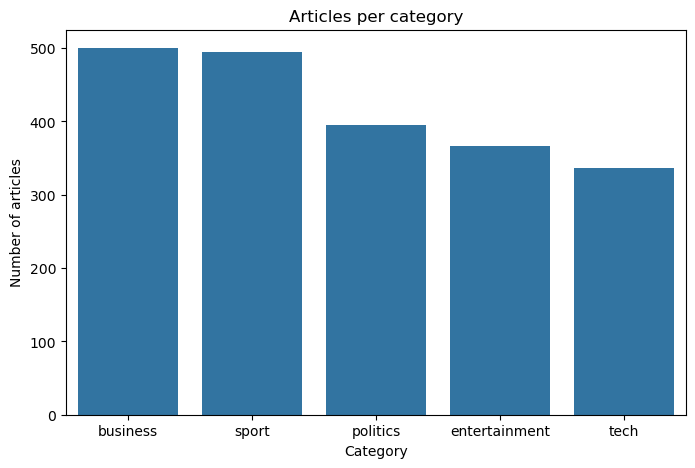

In [8]:
# Visualize category distribution
plt.figure(figsize=(8, 5))
sns.barplot(x=category_counts.index, y=category_counts.values)
plt.title('Articles per category')
plt.xlabel('Category')
plt.ylabel('Number of articles')
plt.show()

In [9]:
# Text length analysis
df['text_length'] = df['content'].str.split().str.len()
print(f"Average text length: {df['text_length'].mean():.0f}")
print(f"Min text length: {df['text_length'].min()}")
print(f"Max text length: {df['text_length'].max()}")

Average text length: 379
Min text length: 84
Max text length: 4428


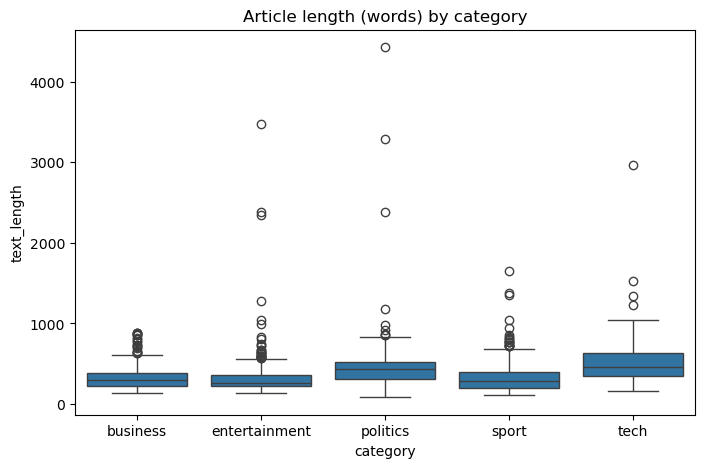

In [10]:
# Visualize text length by category
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='category', y='text_length')
plt.title('Article length (words) by category')
plt.show()

In [11]:
# Map category labels to integers for classification
categories = list(df['category'].unique())
category_mapping = {category: i for i, category in enumerate(categories)}
df['label'] = df['category'].map(category_mapping)
print(category_mapping)

{'business': 0, 'entertainment': 1, 'politics': 2, 'sport': 3, 'tech': 4}


In [12]:
# Rename content column into text for hugging face
df.rename(columns={'content': 'text'}, inplace=True)

In [13]:
# Split into train, validation, and test sets, make sure to stratify based on category, keep features and target together for now
# First, create train+validation and test sets
train_val_df, test_df = train_test_split(
    df, test_size=0.25, stratify=df['category'], random_state=42
)
# Then split train+validation into separate train and validation sets
train_df, val_df = train_test_split(
    train_val_df, test_size=0.2, stratify=train_val_df['category'], random_state=42
)

In [14]:
print(f"Training set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Test set size: {len(test_df)}")

# Ensure categories are distributed properly across splits
print("\nCategory distribution in training set:")
print(train_df['category'].value_counts())
print("\nCategory distribution in validation set:")
print(val_df['category'].value_counts())
print("\nCategory distribution in test set:")
print(test_df['category'].value_counts())

Training set size: 1255
Validation set size: 314
Test set size: 523

Category distribution in training set:
category
business         300
sport            297
politics         237
entertainment    219
tech             202
Name: count, dtype: int64

Category distribution in validation set:
category
business         75
sport            74
politics         59
entertainment    55
tech             51
Name: count, dtype: int64

Category distribution in test set:
category
business         125
sport            123
politics          99
entertainment     92
tech              84
Name: count, dtype: int64


## Part 3: Choose Your Model Approach

### ------- Hugging Face Approach -------
Implement BERT with Hugging Face Transformers
- Import required libraries
- Select and load a BERT model
- Tokenize data
- Create datasets
- Fine-tune the model
- Evaluate performance

In [22]:
# Import Hugging Face libraries
from transformers import BertTokenizer, BertForSequenceClassification
from transformers import Trainer, TrainingArguments, EarlyStoppingCallback
from datasets import Dataset
import torch

# Select and load tokenizer
model_name = 'bert-base-uncased'
tokenizer = BertTokenizer.from_pretrained(model_name)

# Convert pandas DataFrames to Hugging Face datasets
train_dataset_hf = Dataset.from_pandas(train_df, preserve_index=False)
val_dataset_hf = Dataset.from_pandas(val_df, preserve_index=False)
test_dataset_hf = Dataset.from_pandas(test_df, preserve_index=False)

# Tokenize function (use 128 for max length)
def tokenize_function(examples):
    return tokenizer(
        examples['text'],
        padding='max_length',
        truncation=True,
        max_length=128
    )

# Tokenize datasets
tokenized_train = train_dataset_hf.map(tokenize_function, batched=True)
tokenized_val = val_dataset_hf.map(tokenize_function, batched=True)
tokenized_test = test_dataset_hf.map(tokenize_function, batched=True)

Map:   0%|          | 0/1255 [00:00<?, ? examples/s]

Map:   0%|          | 0/314 [00:00<?, ? examples/s]

Map:   0%|          | 0/523 [00:00<?, ? examples/s]

In [23]:
# Sanity check one tokenized example
print(tokenized_train)
sample = tokenized_train[0]
print(sample['category'], '->', sample['label'])
print(tokenizer.decode(sample['input_ids'][:40]))
print(len(sample['input_ids']), 'tokens,', sum(sample['attention_mask']), 'real (non-padding)')

# How much of each article fits in 128 tokens?
full_lengths = np.array([len(tokenizer(t)['input_ids']) for t in train_df['text']])
print(f"Median article length: {np.median(full_lengths):.0f} tokens")
print(f"Articles cut off at 128 tokens: {(full_lengths > 128).mean():.1%}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (707 > 512). Running this sequence through the model will result in indexing errors


Dataset({
    features: ['category', 'filename', 'title', 'text', 'text_length', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1255
})
sport -> 3
[CLS] top - seeded americans andy roddick and andre agassi survived minor scares to reach the last eight of the sap open. agassi endured early problems against left - handed dane kenneth carlsen
128 tokens, 128 real (non-padding)
Median article length: 411 tokens
Articles cut off at 128 tokens: 99.9%


**Tokenization.** I used the `bert-base-uncased` tokenizer because the model was trained with that exact vocabulary. Every article is padded or cut to 128 tokens, as the lab specifies. The "707 > 512" warning is expected: my length check tokenizes without truncation on purpose. The median article is 411 tokens and 99.9% get cut at 128, so the model sees roughly the first third of a typical article.

In [24]:
# Load pre-trained model with classification head
model_hf = BertForSequenceClassification.from_pretrained(
    model_name,
    num_labels=5,
    id2label={i: c for c, i in category_mapping.items()},
    label2id=category_mapping
)
# Set BERT encoder layers to not train
for param in model_hf.bert.parameters():
    param.requires_grad = False

# Verify what will actually train
trainable = sum(p.numel() for p in model_hf.parameters() if p.requires_grad)
total = sum(p.numel() for p in model_hf.parameters())
print(f"Trainable parameters: {trainable:,} of {total:,}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 3,845 of 109,486,085


**Model.** `bert-base-uncased` with a new 5-class classification head. Following the lab, I froze BERT so only the head trains (3,845 of about 109.5M parameters), which keeps CPU training fast. The "missing classifier weights" warning is expected: that is the new head, randomly initialized.

In [25]:
# Define metrics computation function the returns a dictionary of scores - include at least accuracy
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    # 'weighted' averages per-category scores, weighted by category size
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average='weighted', zero_division=0
    )
    acc = accuracy_score(labels, preds)
    return {'accuracy': acc, 'f1': f1, 'precision': precision, 'recall': recall}

# Set up training arguments (train for 5 epochs - not enough to fully train but for sake of time. Set learning rate of 0.0005)
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    learning_rate=0.0005,
    warmup_steps=40,
    weight_decay=0.01,
    logging_steps=10,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    use_cpu=True,
    report_to='none',
)

# Initialize Trainer - include an early stopping callback with patience of 3
trainer = Trainer(
    model=model_hf,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics,
    processing_class=tokenizer,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

**Training setup.** 5 epochs, batch size 16, learning rate 0.0005 (set by the lab; large, but only the head is training). Warmup is 40 steps, about 10% of my ~395 total steps (the lesson's 500 would be longer than my whole run). After warmup the Trainer decays the learning rate linearly. I keep the best checkpoint by validation accuracy. Early stopping (patience 3) never had a chance to trigger in 5 epochs. Metrics are weighted averages because there are five classes.

In [26]:
# Train the model
print('Fine-tuning BERT model with Hugging Face...')
trainer.train()

Fine-tuning BERT model with Hugging Face...


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,1.541294,1.452504,0.420382,0.406119,0.638390,0.420382
2,1.337111,1.295218,0.563694,0.532582,0.637412,0.563694
3,1.218103,1.212665,0.589172,0.543110,0.670702,0.589172
4,1.201945,1.190184,0.627389,0.581956,0.701638,0.627389
5,1.174685,1.164734,0.649682,0.632085,0.730969,0.649682


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=395, training_loss=1.3284548554239395, metrics={'train_runtime': 1042.8784, 'train_samples_per_second': 6.017, 'train_steps_per_second': 0.379, 'total_flos': 412766585990400.0, 'train_loss': 1.3284548554239395, 'epoch': 5.0})

In [ ]:
# Sanity check: best checkpoint should reproduce the epoch-5 validation score
print(trainer.evaluate(tokenized_val))

Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
1.174685,1.164734,5,0.649682,0.632085,0.730969,0.649682


{'eval_loss': 1.1647342443466187, 'eval_accuracy': 0.6496815286624203, 'eval_f1': 0.6320852667796619, 'eval_precision': 0.7309687340457743, 'eval_recall': 0.6496815286624203}


In [28]:
# Evaluate the model
results = trainer.evaluate(tokenized_test)
print(f"Hugging Face Model Results: {results}")

Training Loss,Validation Loss,Epoch,Accuracy,F1,Precision,Recall
1.174685,1.173160,5,0.661568,0.652208,0.731093,0.661568


Hugging Face Model Results: {'eval_loss': 1.1731595993041992, 'eval_accuracy': 0.6615678776290631, 'eval_f1': 0.6522083075517957, 'eval_precision': 0.7310930910469587, 'eval_recall': 0.6615678776290631}


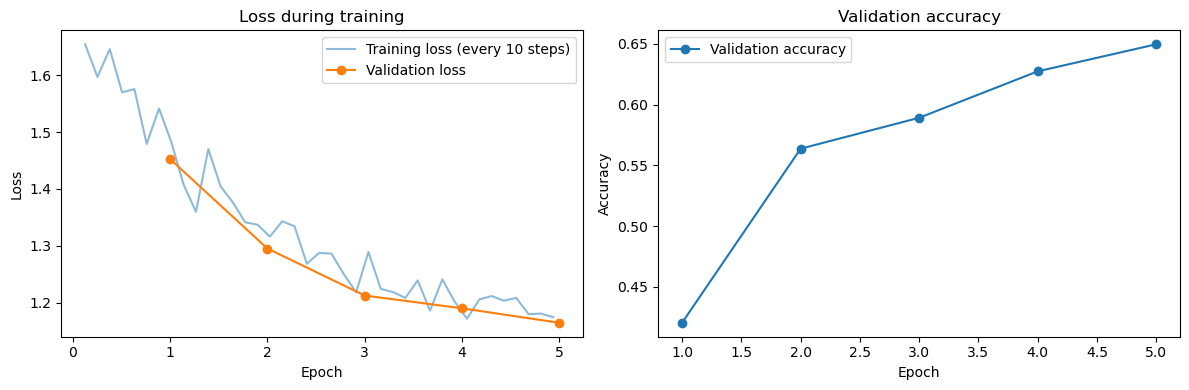

In [30]:
log = pd.DataFrame(trainer.state.log_history)
train_log = log[log['loss'].notna()]
eval_log = log[log['eval_loss'].notna()].drop_duplicates(subset='epoch', keep='first')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_log['epoch'], train_log['loss'], alpha=0.5, label='Training loss (every 10 steps)')
axes[0].plot(eval_log['epoch'], eval_log['eval_loss'], marker='o', label='Validation loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()
axes[0].set_title('Loss during training')

axes[1].plot(eval_log['epoch'], eval_log['eval_accuracy'], marker='o', label='Validation accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()
axes[1].set_title('Validation accuracy')

plt.tight_layout()
plt.show()

**Training curves.** Training and validation loss fall together and neither has leveled off at epoch 5. Validation accuracy rose every epoch (42% to 65%). There's no sign of overfitting; the model is undertrained.

## Part 4: Model Analysis and Inference
Analyze model performance on testing data
- Create confusion matrix visualization
- Analyze misclassifications
- Identify strengths and weaknesses

### Hugging Face Model

<Figure size 1000x800 with 0 Axes>

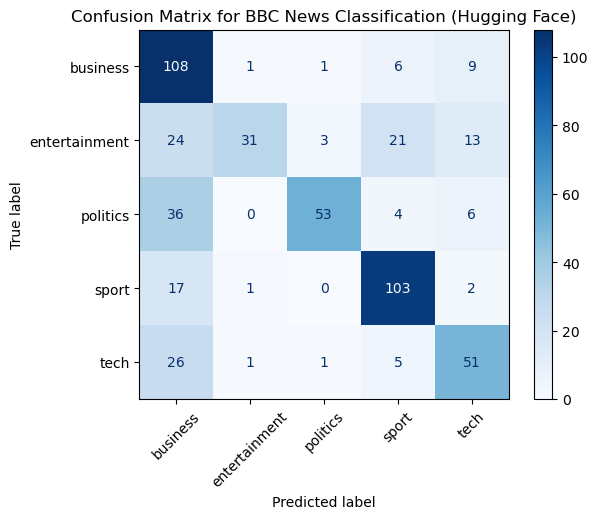


Classification Report:
               precision    recall  f1-score   support

     business       0.51      0.86      0.64       125
entertainment       0.91      0.34      0.49        92
     politics       0.91      0.54      0.68        99
        sport       0.74      0.84      0.79       123
         tech       0.63      0.61      0.62        84

     accuracy                           0.66       523
    macro avg       0.74      0.64      0.64       523
 weighted avg       0.73      0.66      0.65       523



In [33]:
# Generate predictions for the test set
def get_predictions(trainer, dataset):
    raw_predictions = trainer.predict(dataset)
    predictions = np.argmax(raw_predictions.predictions, axis=1)
    labels = raw_predictions.label_ids
    return predictions, labels

y_pred, y_true = get_predictions(trainer, tokenized_test)

# Create and visualize the confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=categories)
disp.plot(cmap='Blues', values_format='d', xticks_rotation=45)
plt.title('Confusion Matrix for BBC News Classification (Hugging Face)')
plt.grid(False)
plt.show()

# Create classification report
report = classification_report(y_true, y_pred, target_names=categories, output_dict=True, zero_division=0)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=categories, zero_division=0))


Model Strengths and Weaknesses:

Strengths:
- Overall accuracy: 0.6616
- Best performing category: sport

Weaknesses:
- Worst performing category: entertainment


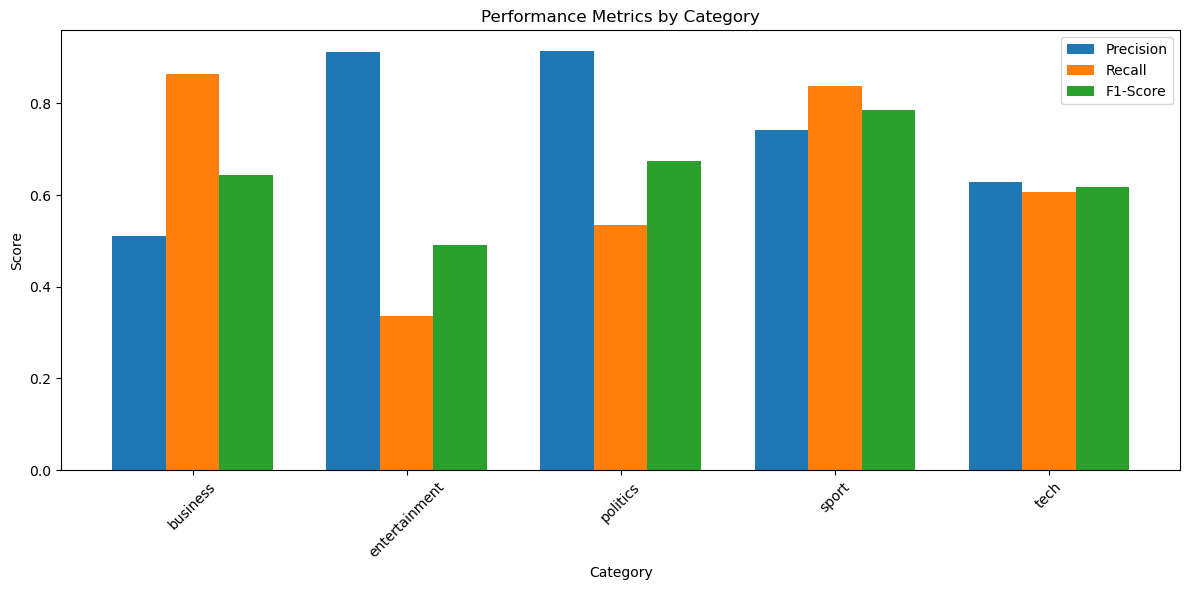

In [34]:
# Identify strengths and weaknesses
print("\nModel Strengths and Weaknesses:")

# Calculate per-class metrics (use classification report)
per_class_metrics = {cat: report[cat] for cat in categories}

# Find best and worst performing categories
best_category = max(per_class_metrics.items(), key=lambda x: x[1]['f1-score'])
worst_category = min(per_class_metrics.items(), key=lambda x: x[1]['f1-score'])

print(f"\nStrengths:")
print(f"- Overall accuracy: {report['accuracy']:.4f}")
print(f"- Best performing category: {best_category[0]}")
print(f"\nWeaknesses:")
print(f"- Worst performing category: {worst_category[0]}")

# Visualize per-class performance
plt.figure(figsize=(12, 6))
categories_indices = range(len(categories))
width = 0.25

plt.bar([i - width for i in categories_indices],
        [per_class_metrics[cat]['precision'] for cat in categories],
        width=width, label='Precision')
plt.bar(categories_indices,
        [per_class_metrics[cat]['recall'] for cat in categories],
        width=width, label='Recall')
plt.bar([i + width for i in categories_indices],
        [per_class_metrics[cat]['f1-score'] for cat in categories],
        width=width, label='F1-Score')

plt.xlabel('Category')
plt.ylabel('Score')
plt.title('Performance Metrics by Category')
plt.xticks(categories_indices, categories, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
# Predictions line up with test_df row order (same order we built the HF dataset from)
errors = test_df.reset_index(drop=True).copy()
errors['pred'] = [categories[i] for i in y_pred]
wrong = errors[errors['category'] != errors['pred']]
print(f"{len(wrong)} misclassified out of {len(errors)}")

# Most common (true -> predicted) mistakes
display(wrong.groupby(['category', 'pred']).size().sort_values(ascending=False).head(8))

def show_errors(true_cat, n=4):
    subset = wrong[wrong['category'] == true_cat]
    for _, row in subset.sample(min(n, len(subset)), random_state=42).iterrows():
        print(f"TRUE: {row['category']} | PRED: {row['pred']}")
        print(f"Title: {row['title']}")
        print(' '.join(row['text'].split()[:100]) + '...\n')

show_errors('entertainment')

177 misclassified out of 523


category       pred    
politics       business    36
tech           business    26
entertainment  business    24
               sport       21
sport          business    17
entertainment  tech        13
business       tech         9
               sport        6
dtype: int64

TRUE: entertainment | PRED: business
Title: Dutch watch Van Gogh's last film
The last film to be made by the slain Dutch director Theo van Gogh, called 06/05, has been premiered in The Hague. Members of Van Gogh's family and celebrities attended the screening of 06/05, based on the murder of the anti-immigration politician Pim Fortuyn. Van Gogh was shot and stabbed to death in Amsterdam six weeks ago. A Dutch-Moroccan man suspected of radical Islamist links has been charged. The killing, and Fortuyn's death in 2002, convulsed the Netherlands. Many Dutch people have questioned their country's self-image as a peaceful, tolerant nation in the wake of the murders, which triggered heated...

TRUE: entertainment | PRED: business
Title: Day-Lewis set for Berlin honour
Actor Daniel Day-Lewis is to be presented with an award for his career in film at the Berlin Film Festival. The 47-year-old, whose credits include his Oscar-winning performance in My Left Foot, will be presented with the Berlina

In [36]:
show_errors('politics')

TRUE: politics | PRED: business
Title: Women MPs reveal sexist taunts
Women MPs endure "shocking" levels of sexist abuse at the hands of their male counterparts, a new study shows. Male MPs pretended to juggle imaginary breasts and jeered "melons" as women made Commons speeches, researchers from Birkbeck College were told. Labour's Yvette Cooper said she found it hard to persuade Commons officials she was a minister and not a secretary. Some 83 MPs gave their answers in 100 hours of taped interviews for the study "Whose Secretary are You, minister". The research team, under Professor Joni Lovenduski, had set out to look at the achievements and experiences of women at...

TRUE: politics | PRED: business
Title: Ban on hunting comes into force
Fox hunting with dogs is now illegal in England and Wales after a ban on the activity came into force overnight. The law faces a stiff test this weekend, with the Countryside Alliance saying many hunts will be out in force. Chief police officers spo

Error analysis. About 34% of test articles (177 of 523) were misclassified. The biggest problem is that the model over-predicts business: 40% of its predictions were business, but only 24% of test articles are. Reading examples, most mistakes weren’t ambiguous articles. A Daniel Day-Lewis film award and a fox hunting ban were both labeled business. That suggests the model is undertrained, not that the categories are inherently fuzzy. Entertainment and politics have high precision (0.91) but low recall (0.34 and 0.54), so the model rarely predicts them, but is usually right when it does.

In [ ]:
# Create a function for model inference on new articles
def predict_article_category(text, model=model_hf, tokenizer=tokenizer):
    """
    Predict the category of a news article using the fine-tuned model.

    Args:
        text (str): The text of the news article
        model: The fine-tuned Hugging Face model
        tokenizer: The tokenizer for the model

    Returns:
        dict: Prediction results including category and confidence scores
    """
    model.eval()

    # Tokenize inputs
    inputs = tokenizer(
        text,
        padding='max_length',
        truncation=True,
        max_length=128,
        return_tensors='pt'
    )

    # Get predictions
    with torch.no_grad():
        outputs = model(**inputs)

    # Convert to numpy for easier handling
    probs = torch.softmax(outputs.logits, dim=1)[0].numpy()

    # Get the predicted category and confidence
    predicted_class_id = int(np.argmax(probs))
    predicted_category = categories[predicted_class_id]
    confidence = float(probs[predicted_class_id])

    # Get confidence for all categories
    category_confidences = {categories[i]: float(probs[i]) for i in range(len(categories))}

    # Sort categories by confidence (descending)
    sorted_categories = sorted(category_confidences.items(), key=lambda x: x[1], reverse=True)

    return {
        'text': text[:100] + '...' if len(text) > 100 else text,
        'predicted_category': predicted_category,
        'confidence': confidence,
        'all_confidences': sorted_categories
    }

# Test the inference function with example articles
sample_articles = [
    "The tech giant announced the release of their new smartphone that features advanced AI capabilities and improved battery life. The product will be available in stores next month.",
    "The football team secured their victory in the final minutes with a spectacular goal. The win puts them at the top of the league table.",
    "Stock markets plummeted following the central bank's announcement of interest rate increases. Investors are concerned about the impact on economic growth.",
    "The new film starring the award-winning actress has received critical acclaim at the international film festival. Critics praised the innovative cinematography.",
    "The government announced new policies regarding digital privacy and data protection. Opposition parties have criticized the measures as inadequate."
]

print("\nTesting inference on sample articles:")
for i, article in enumerate(sample_articles):
    result = predict_article_category(article)
    print(f"\nSample {i+1}:")
    print(f"Text: {result['text']}")
    print(f"Predicted category: {result['predicted_category']} (confidence: {result['confidence']:.4f})")
    print("All category confidences:")
    for category, conf in result['all_confidences']:
        print(f"  - {category}: {conf:.4f}")


Testing inference on sample articles:

Sample 1:
Text: The tech giant announced the release of their new smartphone that features advanced AI capabilities ...
Predicted category: business (confidence: 0.4271)
All category confidences:
  - business: 0.4271
  - tech: 0.1563
  - politics: 0.1529
  - entertainment: 0.1414
  - sport: 0.1223

Sample 2:
Text: The football team secured their victory in the final minutes with a spectacular goal. The win puts t...
Predicted category: sport (confidence: 0.3284)
All category confidences:
  - sport: 0.3284
  - entertainment: 0.2461
  - business: 0.2034
  - politics: 0.1417
  - tech: 0.0804

Sample 3:
Text: Stock markets plummeted following the central bank's announcement of interest rate increases. Invest...
Predicted category: business (confidence: 0.5359)
All category confidences:
  - business: 0.5359
  - politics: 0.2159
  - tech: 0.1262
  - entertainment: 0.0650
  - sport: 0.0570

Sample 4:
Text: The new film starring the award-winning actress

Inference. predict_article_category tokenizes the article exactly as in training (lowercased word pieces, truncated or padded to 128 tokens), runs it through the fine-tuned model with gradients off, and converts the five raw scores into probabilities with softmax. It returns the top category plus all five confidences. On five hand-written samples it got 3 right. The two misses were both predicted as business, consistent with the over-prediction seen in the confusion matrix. Confidences were low even for correct answers (33–57%), so I wouldn’t trust them as calibrated probabilities.

# Part 5: Conclusion and Discussion
Summarize your findings
- What was the final accuracy and other metrics?
- What categories were easiest/hardest to classify?
- What challenges did you encounter?
- How might you improve the model further?


## Results
I fine-tuned `bert-base-uncased` with Hugging Face, with the BERT layers frozen so only the 5-class classification head trained (5 epochs, learning rate 0.0005, batch size 16, max length 128). On the test set (523 articles) the model reached **66.2% accuracy**, with a weighted F1 of 0.65, weighted precision of 0.73, and weighted recall of 0.66. Validation accuracy was 65.0%, so the test score was consistent and I don't think the validation set misled me. For reference, guessing at random would get about 20%.

## Easiest and hardest categories
- **Easiest: sport** (F1 0.79, recall 0.84).
- **Hardest: entertainment** (F1 0.49). Precision was 0.91 but recall was only 0.34, so when the model said "entertainment" it was nearly always right, but it only found about a third of the real entertainment articles.
- Politics showed the same pattern (precision 0.91, recall 0.54).
- The model **over-predicts business**: 40% of its predictions were business, but only 24% of test articles are. Business has the best recall (0.86) and the worst precision (0.51). Most of the errors were politics, tech, and entertainment articles that got labeled business.

## What the error analysis showed
177 of 523 articles were misclassified. When I read examples, most of the mistakes were not ambiguous. A Daniel Day-Lewis film award, a Radio 1 chart show, and the fox hunting ban were all labeled business. A person would get these right from the first sentence. That suggests the model is undertrained rather than the categories being inherently fuzzy. This is based on reading a handful of examples, not a systematic review. The training curves point the same way: training and validation loss fell together and were still falling at epoch 5, with no overfitting. On five hand-written sample articles, the inference function got 3 right, and both misses were predicted as business. Its confidence was low even when correct (33-57%), and I wouldn't treat those numbers as real probabilities.

## Challenges
- The data file was named `.csv` but was actually tab-separated, so my first load failed until I used `sep='\t'`.
- The dataset had 133 exact duplicate articles. I removed them before splitting so copies couldn't land in both train and test and inflate the score. This only catches exact copies, not rewritten versions of the same story.
- Mixing `pip` installs into the conda environment caused a `pyarrow` version error that a kernel restart fixed.
- The lesson's code didn't transfer directly. The metric function used `average='binary'`, which breaks with five classes, so I switched to weighted averages. The 500 warmup steps were also scaled down to 40, because my whole run was only 395 steps.
- Running cells out of order after a kernel restart silently brought the duplicates back until I noticed the split sizes were off.

## How I would improve it
I did not run these, so they are ideas, not results.
1. **Unfreeze BERT and fine-tune it** with a much smaller learning rate (around 2e-5). I suspect the frozen BERT's summary vector is a weak signal for topic, and this is the standard fix. It's the first thing I'd try, but I didn't test whether freezing is actually the cause. Training would be slower on CPU.
2. **Train longer.** Every metric was still improving at epoch 5.
3. **Use a longer max length** (256 or 512). 99.9% of articles were cut off at 128 tokens (median length is 411). The topic usually shows up in the first sentence, so I don't think this is the main problem, but it could help.
4. **Compare against a simple baseline** such as TF-IDF with logistic regression. I'd expect it to score well on this kind of data, which would show whether BERT is the right tool here.
5. **Check for near-duplicates** and consider class weights, since the model leans so heavily on business.